In [4]:
!pip install -q pandas numpy scikit-learn matplotlib seaborn

In [5]:
import pandas as pd
import numpy as np
import re

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

print("✅ All libraries imported successfully!")

✅ All libraries imported successfully!


In [6]:
# STEP 3 - Create Product Dataset

products = {
    "product_id": [
        1, 2, 3, 4, 5,
        6, 7, 8, 9, 10,
        11, 12, 13, 14, 15,
        16, 17, 18, 19, 20
    ],

    "product_name": [
        "Lenovo IdeaPad Slim 3",
        "HP 15s",
        "ASUS VivoBook 15",
        "Dell Inspiron 15",
        "Acer Aspire 5",
        "Samsung Galaxy A55",
        "OnePlus Nord CE 4",
        "Redmi Note 13 Pro",
        "Realme 13 Pro",
        "Nothing Phone 2a",
        "Sony WH-CH520",
        "JBL Tune 770NC",
        "boAt Rockerz 450",
        "Apple AirPods 4",
        "Samsung Galaxy Buds FE",
        "Samsung Galaxy Tab S9 FE",
        "OnePlus Pad Go",
        "Apple iPad 10th Gen",
        "Canon EOS 2000D",
        "Sony Alpha ZV-E10"
    ],

    "category": [
        "Laptop", "Laptop", "Laptop", "Laptop", "Laptop",
        "Smartphone", "Smartphone", "Smartphone", "Smartphone", "Smartphone",
        "Headphones", "Headphones", "Headphones", "Headphones", "Headphones",
        "Tablet", "Tablet", "Tablet", "Camera", "Camera"
    ],

    "brand": [
        "Lenovo", "HP", "ASUS", "Dell", "Acer",
        "Samsung", "OnePlus", "Redmi", "Realme", "Nothing",
        "Sony", "JBL", "boAt", "Apple", "Samsung",
        "Samsung", "OnePlus", "Apple", "Canon", "Sony"
    ],

    "price": [
        55999, 58990, 59990, 64990, 52990,
        38999, 24999, 29999, 27999, 27999,
        4499, 5999, 1999, 12999, 4999,
        32999, 19999, 39999, 42999, 69999
    ],

    "rating": [
        4.3, 4.2, 4.4, 4.3, 4.2,
        4.5, 4.4, 4.3, 4.2, 4.4,
        4.5, 4.4, 4.1, 4.6, 4.3,
        4.5, 4.3, 4.6, 4.4, 4.5
    ],

    "description": [
        "15.6 inch laptop AMD Ryzen 5 8GB RAM 512GB SSD suitable for programming students and everyday work",
        "15.6 inch laptop Intel Core i5 16GB RAM 512GB SSD suitable for programming office work and students",
        "15.6 inch laptop Intel Core i5 16GB RAM 512GB SSD suitable for coding programming and productivity",
        "15.6 inch laptop Intel Core i5 16GB RAM 512GB SSD suitable for professional work programming and multitasking",
        "15.6 inch laptop AMD Ryzen 5 8GB RAM 512GB SSD suitable for students programming and daily use",
        "5G smartphone 8GB RAM 128GB storage AMOLED display good camera and battery suitable for photography and everyday use",
        "5G smartphone 8GB RAM 128GB storage fast processor good battery suitable for gaming and everyday performance",
        "5G smartphone 8GB RAM 256GB storage high resolution camera AMOLED display suitable for photography",
        "5G smartphone 8GB RAM 128GB storage excellent camera battery life and performance suitable for entertainment",
        "5G smartphone 8GB RAM 128GB storage OLED display clean software good camera suitable for everyday use",
        "Wireless headphones Bluetooth long battery life lightweight design suitable for music calls and travel",
        "Wireless noise cancelling headphones Bluetooth long battery life suitable for music travel and entertainment",
        "Wireless Bluetooth headphones affordable lightweight design suitable for music students and daily use",
        "Wireless earbuds Bluetooth excellent sound quality suitable for music calls and daily use",
        "Wireless earbuds noise cancellation Bluetooth comfortable fit suitable for music calls and travel",
        "Android tablet 10.9 inch display 6GB RAM 128GB storage suitable for students reading notes and entertainment",
        "Android tablet 11 inch display 8GB RAM 128GB storage suitable for students online classes and entertainment",
        "Tablet 10.9 inch display 64GB storage suitable for students reading drawing entertainment and productivity",
        "DSLR camera 24MP sensor suitable for photography beginners portraits travel and creative projects",
        "Mirrorless camera 24MP sensor suitable for content creation photography video blogging and beginners"
    ]
}

product_df = pd.DataFrame(products)

print("✅ Product dataset created successfully!")
print("Number of products:", len(product_df))

display(product_df.head())

✅ Product dataset created successfully!
Number of products: 20


,product_id,product_name,category,brand,price,rating,description
0,1,Lenovo IdeaPad Slim 3,Laptop,Lenovo,55999,4.3,15.6 inch laptop AMD Ryzen 5 8GB RAM 512GB SSD...
1,2,HP 15s,Laptop,HP,58990,4.2,15.6 inch laptop Intel Core i5 16GB RAM 512GB ...
2,3,ASUS VivoBook 15,Laptop,ASUS,59990,4.4,15.6 inch laptop Intel Core i5 16GB RAM 512GB ...
3,4,Dell Inspiron 15,Laptop,Dell,64990,4.3,15.6 inch laptop Intel Core i5 16GB RAM 512GB ...
4,5,Acer Aspire 5,Laptop,Acer,52990,4.2,15.6 inch laptop AMD Ryzen 5 8GB RAM 512GB SSD...


In [7]:
# STEP 4 - Inspect Product Dataset

print("Dataset Shape:", product_df.shape)

print("\nColumn Names:")
print(product_df.columns.tolist())

print("\nFirst 5 Products:")
display(product_df.head())

print("\nProduct Categories:")
print(product_df["category"].value_counts())

print("\nMissing Values:")
print(product_df.isnull().sum())

Dataset Shape: (20, 7)

Column Names:
['product_id', 'product_name', 'category', 'brand', 'price', 'rating', 'description']

First 5 Products:


,product_id,product_name,category,brand,price,rating,description
0,1,Lenovo IdeaPad Slim 3,Laptop,Lenovo,55999,4.3,15.6 inch laptop AMD Ryzen 5 8GB RAM 512GB SSD...
1,2,HP 15s,Laptop,HP,58990,4.2,15.6 inch laptop Intel Core i5 16GB RAM 512GB ...
2,3,ASUS VivoBook 15,Laptop,ASUS,59990,4.4,15.6 inch laptop Intel Core i5 16GB RAM 512GB ...
3,4,Dell Inspiron 15,Laptop,Dell,64990,4.3,15.6 inch laptop Intel Core i5 16GB RAM 512GB ...
4,5,Acer Aspire 5,Laptop,Acer,52990,4.2,15.6 inch laptop AMD Ryzen 5 8GB RAM 512GB SSD...



Product Categories:
category
Laptop        5
Smartphone    5
Headphones    5
Tablet        3
Camera        2
Name: count, dtype: int64

Missing Values:
product_id      0
product_name    0
category        0
brand           0
price           0
rating          0
description     0
dtype: int64


In [8]:
# STEP 5 - Clean Product Text

def clean_text(text):
    text = str(text).lower()
    text = re.sub(r'[^a-zA-Z0-9\s]', '', text)
    text = re.sub(r'\s+', ' ', text).strip()
    return text


# Clean the product descriptions
product_df["clean_description"] = product_df["description"].apply(clean_text)

print("✅ Product descriptions cleaned successfully!")

display(
    product_df[
        ["product_name", "description", "clean_description"]
    ].head()
)

✅ Product descriptions cleaned successfully!


,product_name,description,clean_description
0,Lenovo IdeaPad Slim 3,15.6 inch laptop AMD Ryzen 5 8GB RAM 512GB SSD...,156 inch laptop amd ryzen 5 8gb ram 512gb ssd ...
1,HP 15s,15.6 inch laptop Intel Core i5 16GB RAM 512GB ...,156 inch laptop intel core i5 16gb ram 512gb s...
2,ASUS VivoBook 15,15.6 inch laptop Intel Core i5 16GB RAM 512GB ...,156 inch laptop intel core i5 16gb ram 512gb s...
3,Dell Inspiron 15,15.6 inch laptop Intel Core i5 16GB RAM 512GB ...,156 inch laptop intel core i5 16gb ram 512gb s...
4,Acer Aspire 5,15.6 inch laptop AMD Ryzen 5 8GB RAM 512GB SSD...,156 inch laptop amd ryzen 5 8gb ram 512gb ssd ...


In [9]:
# STEP 6 - Create Searchable Product Text

product_df["search_text"] = (
    product_df["product_name"] + " " +
    product_df["category"] + " " +
    product_df["brand"] + " " +
    product_df["clean_description"]
)

print("✅ Searchable product text created successfully!")

display(
    product_df[
        ["product_name", "category", "brand", "search_text"]
    ].head()
)

✅ Searchable product text created successfully!


,product_name,category,brand,search_text
0,Lenovo IdeaPad Slim 3,Laptop,Lenovo,Lenovo IdeaPad Slim 3 Laptop Lenovo 156 inch l...
1,HP 15s,Laptop,HP,HP 15s Laptop HP 156 inch laptop intel core i5...
2,ASUS VivoBook 15,Laptop,ASUS,ASUS VivoBook 15 Laptop ASUS 156 inch laptop i...
3,Dell Inspiron 15,Laptop,Dell,Dell Inspiron 15 Laptop Dell 156 inch laptop i...
4,Acer Aspire 5,Laptop,Acer,Acer Aspire 5 Laptop Acer 156 inch laptop amd ...


In [10]:
# STEP 7 - TF-IDF Vectorization

vectorizer = TfidfVectorizer(
    stop_words="english"
)

product_vectors = vectorizer.fit_transform(
    product_df["search_text"]
)

print("✅ TF-IDF vectorization completed!")
print("Vector shape:", product_vectors.shape)

✅ TF-IDF vectorization completed!
Vector shape: (20, 139)


In [11]:
# STEP 8 - Product Recommendation Function

def recommend_products(query, top_n=5):

    # Convert user query into TF-IDF vector
    query_vector = vectorizer.transform([query])

    # Calculate similarity between query and all products
    similarity_scores = cosine_similarity(
        query_vector,
        product_vectors
    ).flatten()

    # Get indexes of the most similar products
    top_indices = similarity_scores.argsort()[::-1][:top_n]

    # Create recommendation result
    recommendations = product_df.iloc[top_indices].copy()

    # Add similarity score
    recommendations["similarity_score"] = similarity_scores[top_indices]

    return recommendations[
        [
            "product_name",
            "category",
            "brand",
            "price",
            "rating",
            "similarity_score"
        ]
    ]


print("✅ Recommendation function created successfully!")

✅ Recommendation function created successfully!


In [12]:
# STEP 9 - Test Product Recommendations

query = "I need a laptop for programming"

recommendations = recommend_products(query, top_n=5)

print("🔎 User Query:")
print(query)

print("\n💡 Recommended Products:")
display(recommendations)

🔎 User Query:
I need a laptop for programming

💡 Recommended Products:


,product_name,category,brand,price,rating,similarity_score
4,Acer Aspire 5,Laptop,Acer,52990,4.2,0.403695
0,Lenovo IdeaPad Slim 3,Laptop,Lenovo,55999,4.3,0.387337
1,HP 15s,Laptop,HP,58990,4.2,0.385360
2,ASUS VivoBook 15,Laptop,ASUS,59990,4.4,0.377549
3,Dell Inspiron 15,Laptop,Dell,64990,4.3,0.366700


In [13]:
# STEP 10 - Product Recommendation with Price Filter

def recommend_with_price(query, max_price=None, top_n=5):

    # Convert query into TF-IDF vector
    query_vector = vectorizer.transform([query])

    # Calculate similarity scores
    similarity_scores = cosine_similarity(
        query_vector,
        product_vectors
    ).flatten()

    # Create a copy of the product dataset
    results = product_df.copy()

    # Add similarity score
    results["similarity_score"] = similarity_scores

    # Apply price filter if provided
    if max_price is not None:
        results = results[results["price"] <= max_price]

    # Sort by similarity score
    results = results.sort_values(
        by="similarity_score",
        ascending=False
    )

    # Return top recommendations
    return results[
        [
            "product_name",
            "category",
            "brand",
            "price",
            "rating",
            "similarity_score"
        ]
    ].head(top_n)


print("✅ Price-filtered recommendation function created!")

✅ Price-filtered recommendation function created!


In [14]:
query = "laptop for programming"

recommendations = recommend_with_price(
    query,
    max_price=60000,
    top_n=5
)

print("🔎 Query:", query)
print("💰 Maximum Budget: ₹60,000")

display(recommendations)

🔎 Query: laptop for programming
💰 Maximum Budget: ₹60,000


,product_name,category,brand,price,rating,similarity_score
4,Acer Aspire 5,Laptop,Acer,52990,4.2,0.403695
0,Lenovo IdeaPad Slim 3,Laptop,Lenovo,55999,4.3,0.387337
1,HP 15s,Laptop,HP,58990,4.2,0.385360
2,ASUS VivoBook 15,Laptop,ASUS,59990,4.4,0.377549
5,Samsung Galaxy A55,Smartphone,Samsung,38999,4.5,0.000000


In [15]:
# STEP 11 - Detect Product Category

def detect_category(query):
    query = query.lower()

    if "laptop" in query or "notebook" in query or "computer" in query:
        return "Laptop"

    elif "phone" in query or "smartphone" in query or "mobile" in query:
        return "Smartphone"

    elif "headphone" in query or "headphones" in query or "earbuds" in query:
        return "Headphones"

    elif "tablet" in query or "tab" in query:
        return "Tablet"

    elif "camera" in query or "dslr" in query or "mirrorless" in query:
        return "Camera"

    else:
        return None


print("✅ Category detection function created!")

✅ Category detection function created!


In [16]:
test_queries = [
    "I need a laptop for programming",
    "Suggest a phone for gaming",
    "I need headphones for music",
    "I want a tablet for studying",
    "Suggest a camera for photography"
]

for query in test_queries:
    category = detect_category(query)
    print(f"Query: {query}")
    print(f"Detected Category: {category}")
    print("-" * 50)

Query: I need a laptop for programming
Detected Category: Laptop
--------------------------------------------------
Query: Suggest a phone for gaming
Detected Category: Smartphone
--------------------------------------------------
Query: I need headphones for music
Detected Category: Smartphone
--------------------------------------------------
Query: I want a tablet for studying
Detected Category: Tablet
--------------------------------------------------
Query: Suggest a camera for photography
Detected Category: Camera
--------------------------------------------------


In [17]:
# STEP 12 - Smart Product Recommendation

def smart_recommend(query, max_price=None, top_n=5):

    # Detect category from user query
    category = detect_category(query)

    # Convert query into TF-IDF vector
    query_vector = vectorizer.transform([query])

    # Calculate similarity scores
    similarity_scores = cosine_similarity(
        query_vector,
        product_vectors
    ).flatten()

    # Copy product dataset
    results = product_df.copy()

    # Add similarity score
    results["similarity_score"] = similarity_scores

    # Apply category filter
    if category is not None:
        results = results[
            results["category"] == category
        ]

    # Apply price filter
    if max_price is not None:
        results = results[
            results["price"] <= max_price
        ]

    # Sort by similarity score
    results = results.sort_values(
        by="similarity_score",
        ascending=False
    )

    # Return top products
    return results[
        [
            "product_name",
            "category",
            "brand",
            "price",
            "rating",
            "similarity_score"
        ]
    ].head(top_n)


print("✅ Smart recommendation function created!")

✅ Smart recommendation function created!


In [18]:
query = "I need a laptop for programming"

recommendations = smart_recommend(
    query,
    max_price=60000,
    top_n=5
)

print("🔎 Query:", query)
print("📂 Category:", detect_category(query))
print("💰 Maximum Budget: ₹60,000")

display(recommendations)

🔎 Query: I need a laptop for programming
📂 Category: Laptop
💰 Maximum Budget: ₹60,000


,product_name,category,brand,price,rating,similarity_score
4,Acer Aspire 5,Laptop,Acer,52990,4.2,0.403695
0,Lenovo IdeaPad Slim 3,Laptop,Lenovo,55999,4.3,0.387337
1,HP 15s,Laptop,HP,58990,4.2,0.385360
2,ASUS VivoBook 15,Laptop,ASUS,59990,4.4,0.377549


In [19]:
# STEP 13 - Detect Budget from User Query

def detect_budget(query):
    query = query.lower()

    # Find numbers after budget-related words
    patterns = [
        r'under\s+₹?\s*([\d,]+)',
        r'below\s+₹?\s*([\d,]+)',
        r'less\s+than\s+₹?\s*([\d,]+)',
        r'within\s+₹?\s*([\d,]+)',
        r'upto\s+₹?\s*([\d,]+)',
        r'up\s+to\s+₹?\s*([\d,]+)'
    ]

    for pattern in patterns:
        match = re.search(pattern, query)

        if match:
            price = match.group(1).replace(",", "")
            return float(price)

    return None


print("✅ Budget detection function created!")

✅ Budget detection function created!


In [20]:
# Test budget detection

test_queries = [
    "I need a laptop under 60000",
    "Suggest a phone below 30000",
    "Headphones less than 5000",
    "Tablet within 25000",
    "Camera under 70000"
]

for query in test_queries:
    budget = detect_budget(query)

    print("Query:", query)
    print("Detected Budget:", budget)
    print("-" * 50)

Query: I need a laptop under 60000
Detected Budget: 60000.0
--------------------------------------------------
Query: Suggest a phone below 30000
Detected Budget: 30000.0
--------------------------------------------------
Query: Headphones less than 5000
Detected Budget: 5000.0
--------------------------------------------------
Query: Tablet within 25000
Detected Budget: 25000.0
--------------------------------------------------
Query: Camera under 70000
Detected Budget: 70000.0
--------------------------------------------------


In [21]:
# STEP 14 - Final Product Recommendation Chatbot

def product_chatbot(query, top_n=5):

    # Detect category
    category = detect_category(query)

    # Detect budget
    budget = detect_budget(query)

    # Generate recommendations
    recommendations = smart_recommend(
        query,
        max_price=budget,
        top_n=top_n
    )

    # Handle no matching products
    if recommendations.empty:

        print("🤖 Chatbot:")
        print("Sorry, I couldn't find a suitable product matching your requirements.")

        if category:
            print(f"Category: {category}")

        if budget:
            print(f"Maximum Budget: ₹{budget:,.0f}")

        return

    # Display chatbot response
    print("🤖 Chatbot: Here are some products I recommend for you!\n")

    if category:
        print(f"📂 Category: {category}")

    if budget:
        print(f"💰 Maximum Budget: ₹{budget:,.0f}")

    print("\n⭐ Recommended Products:\n")

    display(recommendations)


print("✅ Product recommendation chatbot created successfully!")

✅ Product recommendation chatbot created successfully!


In [22]:
query = "I need a laptop for programming under 60000"

product_chatbot(query)

🤖 Chatbot: Here are some products I recommend for you!

📂 Category: Laptop
💰 Maximum Budget: ₹60,000

⭐ Recommended Products:



,product_name,category,brand,price,rating,similarity_score
4,Acer Aspire 5,Laptop,Acer,52990,4.2,0.403695
0,Lenovo IdeaPad Slim 3,Laptop,Lenovo,55999,4.3,0.387337
1,HP 15s,Laptop,HP,58990,4.2,0.385360
2,ASUS VivoBook 15,Laptop,ASUS,59990,4.4,0.377549


In [23]:
# STEP 15 - Test Multiple Product Queries

test_queries = [
    "I need a laptop for programming under 60000",
    "Suggest a phone for gaming under 30000",
    "I need headphones for music under 7000",
    "Suggest a tablet for studying under 35000",
    "I want a camera for photography under 70000"
]

for query in test_queries:

    print("=" * 70)
    print("👤 User:", query)
    print("=" * 70)

    product_chatbot(query, top_n=3)

    print("\n")

👤 User: I need a laptop for programming under 60000
🤖 Chatbot: Here are some products I recommend for you!

📂 Category: Laptop
💰 Maximum Budget: ₹60,000

⭐ Recommended Products:



,product_name,category,brand,price,rating,similarity_score
4,Acer Aspire 5,Laptop,Acer,52990,4.2,0.403695
0,Lenovo IdeaPad Slim 3,Laptop,Lenovo,55999,4.3,0.387337
1,HP 15s,Laptop,HP,58990,4.2,0.385360




👤 User: Suggest a phone for gaming under 30000
🤖 Chatbot: Here are some products I recommend for you!

📂 Category: Smartphone
💰 Maximum Budget: ₹30,000

⭐ Recommended Products:



,product_name,category,brand,price,rating,similarity_score
9,Nothing Phone 2a,Smartphone,Nothing,27999,4.4,0.213823
6,OnePlus Nord CE 4,Smartphone,OnePlus,24999,4.4,0.188880
7,Redmi Note 13 Pro,Smartphone,Redmi,29999,4.3,0.000000




👤 User: I need headphones for music under 7000
🤖 Chatbot:
Sorry, I couldn't find a suitable product matching your requirements.
Category: Smartphone
Maximum Budget: ₹7,000


👤 User: Suggest a tablet for studying under 35000
🤖 Chatbot: Here are some products I recommend for you!

📂 Category: Tablet
💰 Maximum Budget: ₹35,000

⭐ Recommended Products:



,product_name,category,brand,price,rating,similarity_score
16,OnePlus Pad Go,Tablet,OnePlus,19999,4.3,0.437372
15,Samsung Galaxy Tab S9 FE,Tablet,Samsung,32999,4.5,0.406566




👤 User: I want a camera for photography under 70000
🤖 Chatbot: Here are some products I recommend for you!

📂 Category: Camera
💰 Maximum Budget: ₹70,000

⭐ Recommended Products:



,product_name,category,brand,price,rating,similarity_score
18,Canon EOS 2000D,Camera,Canon,42999,4.4,0.352846
19,Sony Alpha ZV-E10,Camera,Sony,69999,4.5,0.346421


In [24]:
# STEP 16 - Interactive Product Recommendation Chatbot

print("🤖 Product Recommendation Chatbot")
print("Type 'exit' to stop the chatbot.")
print("-" * 60)

while True:

    query = input("\n👤 You: ")

    # Exit condition
    if query.lower().strip() == "exit":
        print("\n🤖 Chatbot: Thank you for using the Product Recommendation Chatbot!")
        break

    # Empty input handling
    if not query.strip():
        print("🤖 Chatbot: Please enter a product requirement.")
        continue

    # Generate recommendations
    product_chatbot(query, top_n=5)

🤖 Product Recommendation Chatbot
Type 'exit' to stop the chatbot.
------------------------------------------------------------

👤 You: laptop
🤖 Chatbot: Here are some products I recommend for you!

📂 Category: Laptop

⭐ Recommended Products:



,product_name,category,brand,price,rating,similarity_score
4,Acer Aspire 5,Laptop,Acer,52990,4.2,0.380607
0,Lenovo IdeaPad Slim 3,Laptop,Lenovo,55999,4.3,0.365184
1,HP 15s,Laptop,HP,58990,4.2,0.363321
2,ASUS VivoBook 15,Laptop,ASUS,59990,4.4,0.355956
3,Dell Inspiron 15,Laptop,Dell,64990,4.3,0.345728



👤 You: exit

🤖 Chatbot: Thank you for using the Product Recommendation Chatbot!


In [25]:
# STEP 17 - Recommendation History

recommendation_history = []

def save_recommendation(query, recommendations):

    if recommendations is None or recommendations.empty:
        return

    for _, row in recommendations.iterrows():

        recommendation_history.append({
            "query": query,
            "product_name": row["product_name"],
            "category": row["category"],
            "brand": row["brand"],
            "price": row["price"],
            "rating": row["rating"],
            "similarity_score": row["similarity_score"]
        })


print("✅ Recommendation history created!")

✅ Recommendation history created!


In [26]:
# Test and save a recommendation

query = "I need a laptop for programming under 60000"

category = detect_category(query)
budget = detect_budget(query)

recommendations = smart_recommend(
    query,
    max_price=budget,
    top_n=5
)

save_recommendation(query, recommendations)

print("✅ Recommendation saved!")
print("Total saved recommendations:", len(recommendation_history))

✅ Recommendation saved!
Total saved recommendations: 4


In [27]:
# STEP 18 - Create Recommendation History DataFrame

# Check whether recommendation history exists
if "recommendation_history" not in globals():
    recommendation_history = []

# If history is empty, create some test recommendations
if len(recommendation_history) == 0:

    test_queries = [
        "I need a laptop for programming under 60000",
        "Suggest a phone for gaming under 30000",
        "I need headphones for music under 7000"
    ]

    for query in test_queries:

        category = detect_category(query)
        budget = detect_budget(query)

        recommendations = smart_recommend(
            query,
            max_price=budget,
            top_n=5
        )

        save_recommendation(query, recommendations)

# Create DataFrame
history_df = pd.DataFrame(recommendation_history)

print("✅ Recommendation history DataFrame created!")
print("Total records:", len(history_df))

display(history_df)

✅ Recommendation history DataFrame created!
Total records: 4


,query,product_name,category,brand,price,rating,similarity_score
0,I need a laptop for programming under 60000,Acer Aspire 5,Laptop,Acer,52990,4.2,0.403695
1,I need a laptop for programming under 60000,Lenovo IdeaPad Slim 3,Laptop,Lenovo,55999,4.3,0.387337
2,I need a laptop for programming under 60000,HP 15s,Laptop,HP,58990,4.2,0.385360
3,I need a laptop for programming under 60000,ASUS VivoBook 15,Laptop,ASUS,59990,4.4,0.377549


In [28]:
# STEP 19 - Analyze Recommendation Results

print("📊 Recommendation Analysis")
print("=" * 50)

print("\nTotal Recommendations:")
print(len(history_df))

print("\nMost Recommended Categories:")
print(history_df["category"].value_counts())

print("\nAverage Product Price:")
print(f"₹{history_df['price'].mean():,.2f}")

print("\nAverage Product Rating:")
print(f"{history_df['rating'].mean():.2f}")

print("\nAverage Similarity Score:")
print(f"{history_df['similarity_score'].mean():.4f}")

📊 Recommendation Analysis

Total Recommendations:
4

Most Recommended Categories:
category
Laptop    4
Name: count, dtype: int64

Average Product Price:
₹56,992.25

Average Product Rating:
4.28

Average Similarity Score:
0.3885


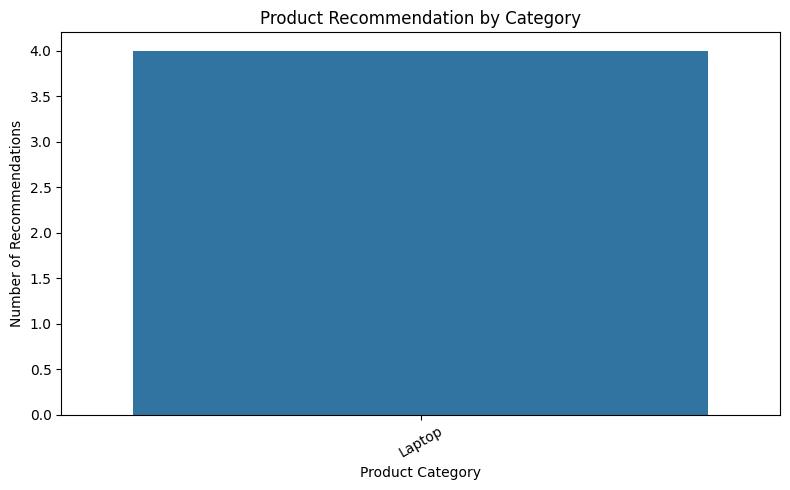

In [29]:
# STEP 20 - Visualize Recommendation Categories

import matplotlib.pyplot as plt
import seaborn as sns

category_counts = history_df["category"].value_counts()

plt.figure(figsize=(8, 5))

sns.barplot(
    x=category_counts.index,
    y=category_counts.values
)

plt.title("Product Recommendation by Category")
plt.xlabel("Product Category")
plt.ylabel("Number of Recommendations")
plt.xticks(rotation=30)

plt.tight_layout()
plt.show()

In [30]:
# STEP 21 - Save Product Dataset

product_df.to_csv(
    "product_dataset.csv",
    index=False
)

print("✅ Product dataset saved successfully!")
print("📁 File name: product_dataset.csv")

✅ Product dataset saved successfully!
📁 File name: product_dataset.csv


In [31]:
# Check saved file

import os

if os.path.exists("product_dataset.csv"):
    print("✅ product_dataset.csv exists!")
else:
    print("❌ File not found.")

✅ product_dataset.csv exists!


In [32]:
# STEP 22 - Save TF-IDF Vectorizer

import pickle

with open("product_tfidf_vectorizer.pkl", "wb") as file:
    pickle.dump(vectorizer, file)

print("✅ TF-IDF vectorizer saved successfully!")
print("📁 File name: product_tfidf_vectorizer.pkl")

✅ TF-IDF vectorizer saved successfully!
📁 File name: product_tfidf_vectorizer.pkl


In [33]:
# Check saved vectorizer file

import os

if os.path.exists("product_tfidf_vectorizer.pkl"):
    print("✅ product_tfidf_vectorizer.pkl exists!")
else:
    print("❌ File not found.")

✅ product_tfidf_vectorizer.pkl exists!


In [34]:
# STEP 23 - Save Recommendation Results

history_df.to_csv(
    "product_recommendation_results.csv",
    index=False
)

print("✅ Recommendation results saved successfully!")
print("📁 File name: product_recommendation_results.csv")

✅ Recommendation results saved successfully!
📁 File name: product_recommendation_results.csv


In [35]:
# Check saved recommendation results

import os

if os.path.exists("product_recommendation_results.csv"):
    print("✅ product_recommendation_results.csv exists!")
else:
    print("❌ File not found.")

✅ product_recommendation_results.csv exists!


In [36]:
# STEP 24 - Create Project Summary

project_summary = pd.DataFrame({
    "Project Name": [
        "AI-Based Product Recommendation Chatbot"
    ],
    "Programming Language": [
        "Python"
    ],
    "Platform": [
        "Google Colab"
    ],
    "Machine Learning Technique": [
        "TF-IDF and Cosine Similarity"
    ],
    "Recommendation Method": [
        "Content-Based Filtering"
    ],
    "Total Products": [
        len(product_df)
    ],
    "Product Categories": [
        ", ".join(product_df["category"].unique())
    ],
    "Dataset File": [
        "product_dataset.csv"
    ],
    "Vectorizer File": [
        "product_tfidf_vectorizer.pkl"
    ],
    "Results File": [
        "product_recommendation_results.csv"
    ]
})

print("✅ Project summary created successfully!")
display(project_summary)

✅ Project summary created successfully!


,Project Name,Programming Language,Platform,Machine Learning Technique,Recommendation Method,Total Products,Product Categories,Dataset File,Vectorizer File,Results File
0,AI-Based Product Recommendation Chatbot,Python,Google Colab,TF-IDF and Cosine Similarity,Content-Based Filtering,20,"Laptop, Smartphone, Headphones, Tablet, Camera",product_dataset.csv,product_tfidf_vectorizer.pkl,product_recommendation_results.csv


In [37]:
# STEP 24 - Create Project Summary

project_summary = pd.DataFrame({
    "Project Detail": [
        "Project Name",
        "Domain",
        "Programming Language",
        "Development Platform",
        "Libraries",
        "Recommendation Technique",
        "Text Processing",
        "Similarity Method",
        "Dataset Size",
        "Main Features"
    ],

    "Description": [
        "AI-Based Product Recommendation Chatbot",
        "Artificial Intelligence and Machine Learning",
        "Python",
        "Google Colab",
        "Pandas, NumPy, Scikit-learn, Matplotlib, Seaborn",
        "Content-Based Filtering",
        "TF-IDF Vectorization",
        "Cosine Similarity",
        f"{len(product_df)} products",
        "Category Detection, Budget Filtering, Product Recommendations, Chatbot Interaction, Recommendation History"
    ]
})

display(project_summary)

project_summary.to_csv(
    "product_recommendation_project_summary.csv",
    index=False
)

print("✅ Project summary saved successfully!")

,Project Detail,Description
0,Project Name,AI-Based Product Recommendation Chatbot
1,Domain,Artificial Intelligence and Machine Learning
2,Programming Language,Python
3,Development Platform,Google Colab
4,Libraries,"Pandas, NumPy, Scikit-learn, Matplotlib, Seaborn"
5,Recommendation Technique,Content-Based Filtering
6,Text Processing,TF-IDF Vectorization
7,Similarity Method,Cosine Similarity
8,Dataset Size,20 products
9,Main Features,"Category Detection, Budget Filtering, Product ..."


✅ Project summary saved successfully!


In [38]:
import os

project_files = [
    "product_dataset.csv",
    "product_tfidf_vectorizer.pkl",
    "product_recommendation_results.csv",
    "product_recommendation_project_summary.csv"
]

print("📁 Project Files")
print("=" * 50)

for file in project_files:
    if os.path.exists(file):
        size = os.path.getsize(file) / 1024
        print(f"✅ {file} — {size:.2f} KB")
    else:
        print(f"❌ {file} — Not Found")

print("\n🎉 File verification completed!")

📁 Project Files
✅ product_dataset.csv — 7.63 KB
✅ product_tfidf_vectorizer.pkl — 3.26 KB
✅ product_recommendation_results.csv — 0.46 KB
✅ product_recommendation_project_summary.csv — 0.51 KB

🎉 File verification completed!


In [39]:
from google.colab import files

project_files = [
    "product_dataset.csv",
    "product_tfidf_vectorizer.pkl",
    "product_recommendation_results.csv",
    "product_recommendation_project_summary.csv"
]

for file in project_files:
    if os.path.exists(file):
        files.download(file)

print("✅ All project files are ready for download!")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

✅ All project files are ready for download!


In [40]:
# STEP 27 - Final Chatbot Testing

final_test_queries = [
    "I need a laptop for programming under 60000",
    "Suggest a smartphone for gaming under 30000",
    "I need headphones for music under 7000",
    "Suggest a tablet for studying under 35000",
    "I want a camera for photography under 70000"
]

print("🤖 FINAL CHATBOT TEST")
print("=" * 70)

for query in final_test_queries:
    print("\n👤 User:", query)
    print("-" * 70)

    product_chatbot(query, top_n=3)

print("\n" + "=" * 70)
print("✅ Final chatbot testing completed!")

🤖 FINAL CHATBOT TEST

👤 User: I need a laptop for programming under 60000
----------------------------------------------------------------------
🤖 Chatbot: Here are some products I recommend for you!

📂 Category: Laptop
💰 Maximum Budget: ₹60,000

⭐ Recommended Products:



,product_name,category,brand,price,rating,similarity_score
4,Acer Aspire 5,Laptop,Acer,52990,4.2,0.403695
0,Lenovo IdeaPad Slim 3,Laptop,Lenovo,55999,4.3,0.387337
1,HP 15s,Laptop,HP,58990,4.2,0.385360



👤 User: Suggest a smartphone for gaming under 30000
----------------------------------------------------------------------
🤖 Chatbot: Here are some products I recommend for you!

📂 Category: Smartphone
💰 Maximum Budget: ₹30,000

⭐ Recommended Products:



,product_name,category,brand,price,rating,similarity_score
6,OnePlus Nord CE 4,Smartphone,OnePlus,24999,4.4,0.422022
9,Nothing Phone 2a,Smartphone,Nothing,27999,4.4,0.226791
8,Realme 13 Pro,Smartphone,Realme,27999,4.2,0.211634



👤 User: I need headphones for music under 7000
----------------------------------------------------------------------
🤖 Chatbot:
Sorry, I couldn't find a suitable product matching your requirements.
Category: Smartphone
Maximum Budget: ₹7,000

👤 User: Suggest a tablet for studying under 35000
----------------------------------------------------------------------
🤖 Chatbot: Here are some products I recommend for you!

📂 Category: Tablet
💰 Maximum Budget: ₹35,000

⭐ Recommended Products:



,product_name,category,brand,price,rating,similarity_score
16,OnePlus Pad Go,Tablet,OnePlus,19999,4.3,0.437372
15,Samsung Galaxy Tab S9 FE,Tablet,Samsung,32999,4.5,0.406566



👤 User: I want a camera for photography under 70000
----------------------------------------------------------------------
🤖 Chatbot: Here are some products I recommend for you!

📂 Category: Camera
💰 Maximum Budget: ₹70,000

⭐ Recommended Products:



,product_name,category,brand,price,rating,similarity_score
18,Canon EOS 2000D,Camera,Canon,42999,4.4,0.352846
19,Sony Alpha ZV-E10,Camera,Sony,69999,4.5,0.346421



✅ Final chatbot testing completed!


In [41]:
# STEP 28 - Final Performance Report

print("📊 PRODUCT RECOMMENDATION CHATBOT")
print("FINAL PERFORMANCE REPORT")
print("=" * 60)

print(f"\n📦 Total Products in Dataset: {len(product_df)}")
print(f"📚 Total Recommendation Records: {len(history_df)}")
print(f"🏷️ Number of Categories: {product_df['category'].nunique()}")

print("\n📂 Categories:")
for category in product_df["category"].unique():
    count = len(product_df[product_df["category"] == category])
    print(f"   • {category}: {count} products")

print("\n💰 Price Statistics:")
print(f"   Minimum Price: ₹{product_df['price'].min():,.0f}")
print(f"   Maximum Price: ₹{product_df['price'].max():,.0f}")
print(f"   Average Price: ₹{product_df['price'].mean():,.2f}")

print("\n⭐ Rating Statistics:")
print(f"   Average Rating: {product_df['rating'].mean():.2f}/5")

print("\n🤖 Recommendation Statistics:")
print(f"   Average Similarity Score: {history_df['similarity_score'].mean():.4f}")

print("\n" + "=" * 60)
print("✅ Final performance report generated successfully!")

📊 PRODUCT RECOMMENDATION CHATBOT
FINAL PERFORMANCE REPORT

📦 Total Products in Dataset: 20
📚 Total Recommendation Records: 4
🏷️ Number of Categories: 5

📂 Categories:
   • Laptop: 5 products
   • Smartphone: 5 products
   • Headphones: 5 products
   • Tablet: 3 products
   • Camera: 2 products

💰 Price Statistics:
   Minimum Price: ₹1,999
   Maximum Price: ₹69,999
   Average Price: ₹33,972.20

⭐ Rating Statistics:
   Average Rating: 4.37/5

🤖 Recommendation Statistics:
   Average Similarity Score: 0.3885

✅ Final performance report generated successfully!


In [42]:
# STEP 29 - Save Final Recommendation Report

final_report = pd.DataFrame({
    "Metric": [
        "Total Products",
        "Total Categories",
        "Recommendation Records",
        "Minimum Product Price",
        "Maximum Product Price",
        "Average Product Price",
        "Average Product Rating",
        "Average Similarity Score"
    ],

    "Value": [
        len(product_df),
        product_df["category"].nunique(),
        len(history_df),
        product_df["price"].min(),
        product_df["price"].max(),
        round(product_df["price"].mean(), 2),
        round(product_df["rating"].mean(), 2),
        round(history_df["similarity_score"].mean(), 4)
    ]
})

display(final_report)

final_report.to_csv(
    "product_recommendation_final_report.csv",
    index=False
)

print("✅ Final recommendation report saved!")
print("📁 File: product_recommendation_final_report.csv")

,Metric,Value
0,Total Products,20.0000
1,Total Categories,5.0000
2,Recommendation Records,4.0000
3,Minimum Product Price,1999.0000
4,Maximum Product Price,69999.0000
5,Average Product Price,33972.2000
6,Average Product Rating,4.3700
7,Average Similarity Score,0.3885


✅ Final recommendation report saved!
📁 File: product_recommendation_final_report.csv
